## EXTRA — Detecção de pneumonia em radiografias de tórax com CNN

### Objetivo

Além do diagnóstico com dados tabulares (câncer de mama), o enunciado do Tech Challenge propõe
um **entregável extra de visão computacional**: diagnosticar uma doença a partir de **imagens**
usando **redes neurais convolucionais (CNN)**. Escolhemos a sugestão do próprio enunciado:
**detecção de pneumonia em radiografias de tórax**.

O problema é de **classificação binária**: dada uma radiografia, estimar a probabilidade de o
paciente ter pneumonia (`1`) ou ser normal (`0`).

**Contexto clínico.** A pneumonia é uma das principais causas de morte em crianças no mundo, e a
radiografia de tórax é o exame mais usado para confirmá-la. Em um hospital com fila crescente de
exames, um modelo que **ordene a fila por suspeita** ajuda o radiologista a ver primeiro os casos
mais prováveis. O modelo é uma ferramenta de **apoio à triagem**: o médico sempre tem a palavra
final sobre o diagnóstico.

**Roteiro do notebook**

1. Setup do ambiente e hiperparâmetros
2. Carga do dataset (PneumoniaMNIST)
3. Exploração das imagens
4. Pré-processamento e *data augmentation*
5. Arquitetura da CNN
6. Treinamento com seleção de época pela ROC AUC de validação
7. Escolha da métrica e calibração do limiar de decisão
8. Avaliação no conjunto de teste
9. Análise de erros
10. Interpretabilidade com Grad-CAM
11. Salvando o modelo
12. Discussão crítica e conclusão

### 1. Setup do ambiente

O projeto usa o **uv** para gerenciar o ambiente. As bibliotecas de visão computacional
(`torch`, `torchvision`, `medmnist`) ficam fora do ambiente principal, em
`requirements-extra.txt`. Na **raiz do projeto**, execute:

```bash
uv sync                                     # ambiente principal (.venv)
uv pip install -r requirements-extra.txt    # dependências extras da CNN
```

Depois selecione o kernel do `.venv` no VS Code / Jupyter.

> Alternativa sem uv (por exemplo, no Google Colab): `pip install -r requirements-extra.txt`.
> Para uma instalação menor, só com CPU:
> `uv pip install --index-url https://download.pytorch.org/whl/cpu torch torchvision`.

A célula abaixo apenas confere se as bibliotecas extras estão instaladas.

In [ ]:
# verifica se as dependencias extras da CNN estao instaladas
import importlib.util

faltando = [lib for lib in ('torch', 'torchvision', 'medmnist') if importlib.util.find_spec(lib) is None]
if faltando:
    raise ImportError(f"Bibliotecas ausentes: {faltando}. "
                      "Na raiz do projeto, execute: uv pip install -r requirements-extra.txt")
print("Dependencias extras instaladas.")

Dependencias extras instaladas.


In [ ]:
# import das libs base necessarias
import copy
import json
import random
import warnings
from dataclasses import dataclass, field
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import transforms
from PIL import Image

import medmnist
from medmnist import INFO

from sklearn.metrics import (
    accuracy_score, average_precision_score, balanced_accuracy_score, brier_score_loss,
    classification_report, confusion_matrix, f1_score, matthews_corrcoef,
    precision_recall_curve, precision_score, recall_score, roc_auc_score, roc_curve,
)

warnings.filterwarnings('ignore')
print(f"torch {torch.__version__} | medmnist {medmnist.__version__}")

torch 2.15.0+cu132 | medmnist 3.0.2


Concentramos todos os hiperparâmetros e caminhos em uma única célula, para facilitar
experimentos. Fixamos a semente aleatória para que os resultados sejam reproduzíveis.

- `IMAGE_SIZE = 64`: resolução das radiografias. O MedMNIST oferece 28, 64, 128 e 224 pixels;
  64×64 é um bom equilíbrio entre detalhe e tempo de treino em CPU.
- `TARGET_RECALL = 0.98`: sensibilidade mínima exigida para pneumonia (justificada na seção 7).
- `DEVICE`: usa GPU se disponível; caso contrário, CPU (o treino leva cerca de 15–20 min em CPU).

In [ ]:
# reprodutibilidade
SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

# hiperparametros
IMAGE_SIZE = 64        # 28, 64, 128 ou 224
EPOCHS = 15
BATCH_SIZE = 128
LR = 1e-3
WEIGHT_DECAY = 1e-4
TARGET_RECALL = 0.98   # sensibilidade minima exigida para pneumonia
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

# caminhos (o notebook roda de dentro de notebooks/)
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA_DIR = ROOT_DIR / 'data' / 'medmnist'
MODELS_DIR = ROOT_DIR / 'models'
DATA_DIR.mkdir(parents=True, exist_ok=True)
(MODELS_DIR / 'metrics').mkdir(parents=True, exist_ok=True)

# estilo dos graficos
CLASS_LABELS = ('Normal', 'Pneumonia')
COR_NORMAL, COR_PNEUMONIA = '#2E7D9A', '#D1495B'
sb.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titleweight': 'bold'})

print(f"Dispositivo: {DEVICE} | dados em: {DATA_DIR}")

Dispositivo: cuda | dados em: /home/vinic/fiap/fase_1/tech_challenge_worktress/cnn_task/data/medmnist


### 2. Dataset: PneumoniaMNIST

O enunciado sugere a base **Chest X-Ray Pneumonia** do Kaggle (Kermany et al., 2018):
radiografias de tórax pediátricas (crianças de 1 a 5 anos) do Guangzhou Women and Children's
Medical Center, rotuladas por especialistas.

Usamos o **PneumoniaMNIST**, parte da coleção **MedMNIST v2** (Yang et al., 2023), que é a
**mesma base de Kermany et al.**, porém padronizada:

- **5.856 radiografias** em tons de cinza, rotuladas como `0 = normal` e `1 = pneumonia`;
- divisão **oficial** em treino / validação / teste, feita pelos autores — garante separação
  clara entre os conjuntos e comparabilidade com a literatura;
- download automático de poucos MB, **sem credenciais do Kaggle**;
- imagens já redimensionadas e centralizadas, o que dispensa etapas de recorte manual.

O download é feito uma única vez para `data/medmnist/` (pasta ignorada pelo Git).

In [ ]:
# metadados oficiais do dataset
DATA_FLAG = 'pneumoniamnist'
info = INFO[DATA_FLAG]
DataClass = getattr(medmnist, info['python_class'])

print(info['description'])
print("\nRotulos:", info['label'])

The PneumoniaMNIST is based on a prior dataset of 5,856 pediatric chest X-Ray images. The task is binary-class classification of pneumonia against normal. We split the source training set with a ratio of 9:1 into training and validation set and use its source validation set as the test set. The source images are gray-scale, and their sizes are (384−2,916)×(127−2,713). We center-crop the images and resize them into 1×28×28.

Rotulos: {'0': 'normal', '1': 'pneumonia'}


In [ ]:
# download (apenas na primeira execucao) dos três splits oficiais, ainda sem transformacoes
kwargs = {'root': str(DATA_DIR), 'download': True}
if IMAGE_SIZE != 28:
    kwargs['size'] = IMAGE_SIZE

raw = {split: DataClass(split=split, **kwargs) for split in ('train', 'val', 'test')}

# imagens em numpy (N, H, W) com valores 0-255 e rotulos (N,)
imgs = {split: np.asarray(ds.imgs) for split, ds in raw.items()}
labels = {split: np.asarray(ds.labels).ravel() for split, ds in raw.items()}

for split in raw:
    print(f"{split:5s}: {imgs[split].shape}  dtype={imgs[split].dtype}")

100%|██████████| 20.6M/20.6M [00:12<00:00, 1.60MB/s]


train: (4708, 64, 64)  dtype=uint8
val  : (524, 64, 64)  dtype=uint8
test : (624, 64, 64)  dtype=uint8


### 3. Exploração das imagens

#### Tamanho dos conjuntos e balanceamento das classes

In [6]:
resumo = pd.DataFrame({
    'imagens': {s: len(labels[s]) for s in labels},
    'normal': {s: int((labels[s] == 0).sum()) for s in labels},
    'pneumonia': {s: int((labels[s] == 1).sum()) for s in labels},
})
resumo['% pneumonia'] = (100 * resumo['pneumonia'] / resumo['imagens']).round(1)
resumo['% do total'] = (100 * resumo['imagens'] / resumo['imagens'].sum()).round(1)
resumo

,imagens,normal,pneumonia,% pneumonia,% do total
train,4708,1214,3494,74.2,80.4
val,524,135,389,74.2,8.9
test,624,234,390,62.5,10.7


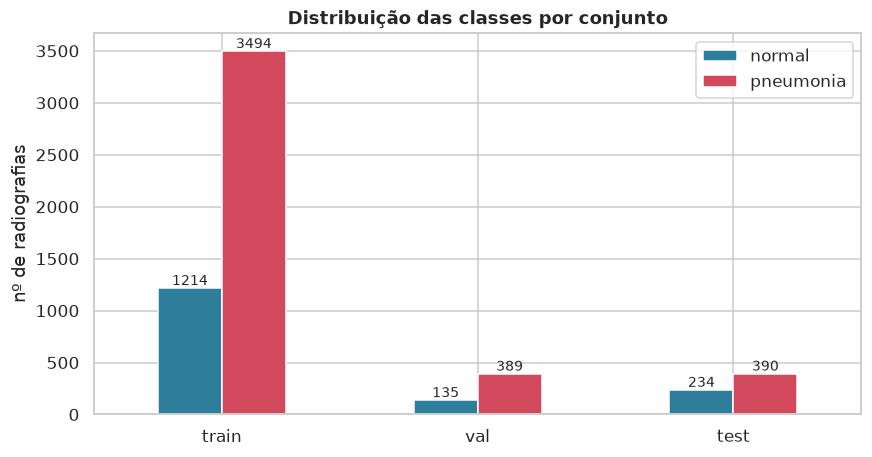

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
resumo[['normal', 'pneumonia']].plot.bar(ax=ax, color=[COR_NORMAL, COR_PNEUMONIA], rot=0)
for container in ax.containers:
    ax.bar_label(container, fontsize=9)
ax.set(title='Distribuição das classes por conjunto', xlabel='', ylabel='nº de radiografias')
plt.show()

A base é **desbalanceada**: cerca de **3 em cada 4 radiografias são de pneumonia** no treino e
na validação. Duas consequências diretas para a modelagem:

- a **acurácia é enganosa** — um modelo que responde sempre "pneumonia" já acerta ~74% no treino
  sem aprender nada;
- precisamos **compensar o desbalanceamento** na função de perda (`pos_weight`, seção 6) e usar
  métricas que não dependem da proporção das classes, como a **ROC AUC**, para selecionar o modelo.

Note também que o conjunto de **teste tem proporção diferente** (~62% de pneumonia). Isso é uma
característica da divisão original de Kermany et al. e torna o teste um cenário mais exigente —
uma pequena mudança de distribuição, como acontece na prática entre hospitais.

#### Exemplos de radiografias

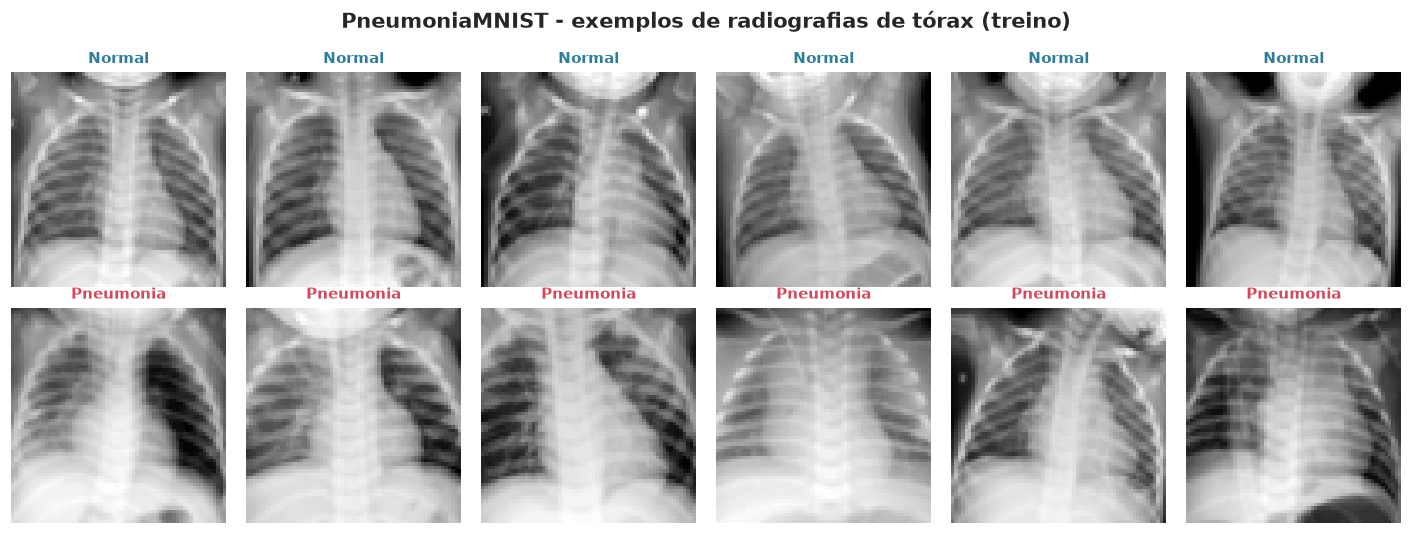

In [ ]:
# 6 exemplos aleatorios de cada classe do treino
rng = np.random.default_rng(SEED)
escolhidos = np.concatenate([rng.choice(np.where(labels['train'] == c)[0], 6, replace=False) for c in (0, 1)])

fig, axes = plt.subplots(2, 6, figsize=(13, 5))
for ax, idx in zip(axes.ravel(), escolhidos):
    y = labels['train'][idx]
    ax.imshow(imgs['train'][idx], cmap='gray')
    ax.set_title(CLASS_LABELS[y], color=COR_NORMAL if y == 0 else COR_PNEUMONIA, fontsize=10)
    ax.axis('off')
fig.suptitle('PneumoniaMNIST - exemplos de radiografias de tórax (treino)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

Nas radiografias **normais**, os pulmões aparecem escuros (o ar não absorve raio-X) e com
contornos bem definidos. Na **pneumonia**, o líquido/inflamação nos alvéolos gera **opacidades**
(regiões esbranquiçadas e difusas) dentro do campo pulmonar. É esse padrão de textura e
intensidade que esperamos que a CNN aprenda.

#### Estatísticas descritivas dos pixels

Para imagens, as "estatísticas descritivas" são calculadas sobre as intensidades dos pixels
(0 = preto, 255 = branco). Comparamos a intensidade média por imagem entre as classes e a
**imagem média** de cada classe.

In [ ]:
# intensidade media e desvio padrao de cada imagem do treino
X_tr = imgs['train'].astype(np.float32)
estat = pd.DataFrame({
    'classe': np.array(CLASS_LABELS)[labels['train']],
    'intensidade_media': X_tr.mean(axis=(1, 2)),
    'contraste_desvio': X_tr.std(axis=(1, 2)),
})
estat.groupby('classe').describe().T.round(1)

classe                   Normal  Pneumonia
intensidade_media count  1214.0     3494.0
                  mean    139.8      147.9
                  std      13.9       21.3
                  min      80.6       70.6
                  25%     130.9      135.5
                  50%     140.4      149.9
                  75%     148.9      163.0
                  max     187.1      225.4
contraste_desvio  count  1214.0     3494.0
                  mean     46.5       35.7
                  std       8.0        8.4
                  min      28.0        7.5
                  25%      40.8       30.4
                  50%      45.6       35.5
                  75%      51.9       40.8
                  max      72.7       69.3

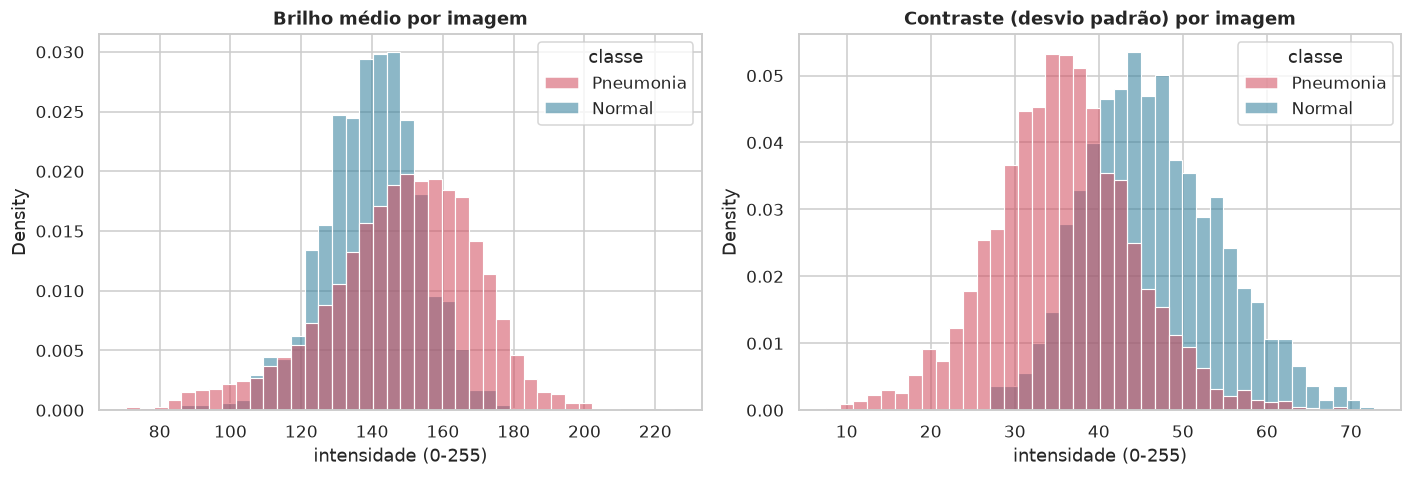

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for col, ax, titulo in zip(['intensidade_media', 'contraste_desvio'], axes,
                           ['Brilho médio por imagem', 'Contraste (desvio padrão) por imagem']):
    sb.histplot(data=estat, x=col, hue='classe', bins=40, stat='density', common_norm=False,
                palette={'Normal': COR_NORMAL, 'Pneumonia': COR_PNEUMONIA}, alpha=0.55, ax=ax)
    ax.set(title=titulo, xlabel='intensidade (0-255)')
plt.tight_layout()
plt.show()

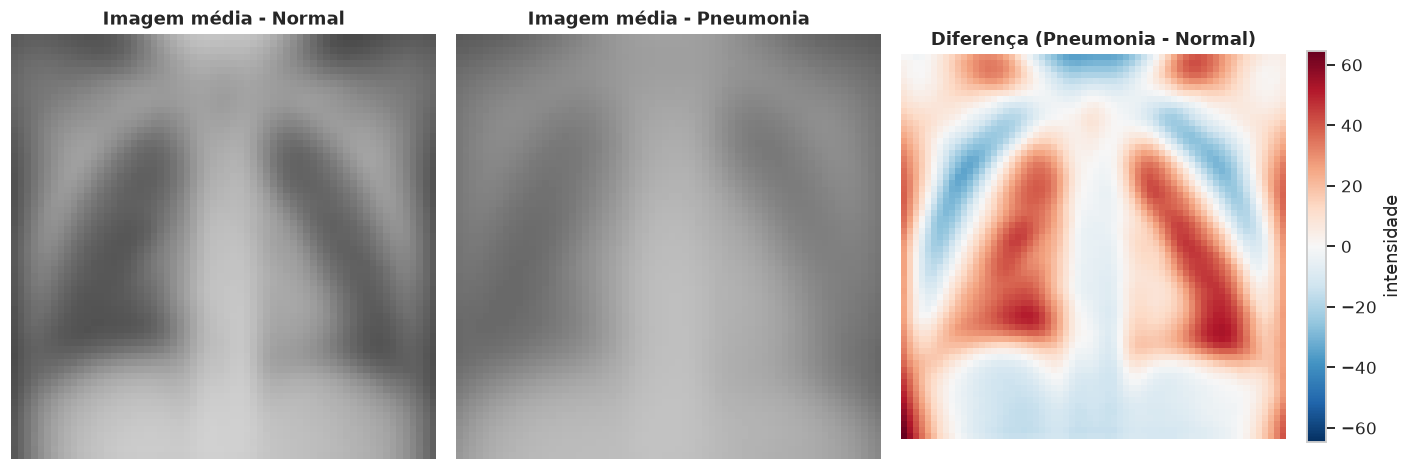

In [ ]:
# imagem media de cada classe e a diferenca entre elas
media_normal = X_tr[labels['train'] == 0].mean(axis=0)
media_pneumonia = X_tr[labels['train'] == 1].mean(axis=0)
diferenca = media_pneumonia - media_normal

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
axes[0].imshow(media_normal, cmap='gray', vmin=0, vmax=255)
axes[0].set_title('Imagem média - Normal')
axes[1].imshow(media_pneumonia, cmap='gray', vmin=0, vmax=255)
axes[1].set_title('Imagem média - Pneumonia')
lim = np.abs(diferenca).max()
im = axes[2].imshow(diferenca, cmap='RdBu_r', vmin=-lim, vmax=lim)
axes[2].set_title('Diferença (Pneumonia - Normal)')
fig.colorbar(im, ax=axes[2], fraction=0.046, label='intensidade')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.show()

As distribuições de brilho e contraste das duas classes se **sobrepõem bastante**: não existe um
limiar simples de intensidade que separe as classes. A diferença está na **distribuição espacial**
dos pixels — a imagem de diferença mostra regiões dentro dos campos pulmonares mais claras na
média das pneumonias (opacidades). Esse tipo de padrão local é exatamente o que as **camadas
convolucionais** capturam, e justifica usar uma CNN em vez de um classificador sobre estatísticas
globais da imagem.

Quanto à qualidade dos dados: não há valores ausentes (todas as imagens têm o mesmo tamanho e
rótulo), e a curadoria do MedMNIST já removeu imagens de baixa qualidade. A limpeza aqui se
resume à **normalização** e ao **aumento de dados**, descritos a seguir.

### 4. Pré-processamento e *data augmentation*

**Normalização.** Convertemos os pixels de 0–255 para 0–1 (`ToTensor`) e depois centralizamos em
torno de zero com `Normalize(mean=0.5, std=0.5)`, levando ao intervalo [-1, 1]. Entradas
centralizadas deixam o treino da rede mais estável.

**Data augmentation (apenas no treino).** A cada época, cada radiografia é levemente alterada
de forma aleatória:

- **espelhamento horizontal**;
- **rotação** de até ±8°, **translação** de até 5% e **zoom** de 95–105%.

Essas transformações simulam variações reais de **posicionamento do paciente** no aparelho e
funcionam como regularização: a rede vê "novas" imagens a cada época e decora menos o treino.
As transformações são pequenas de propósito, para não distorcer a anatomia. Validação e teste
**não** recebem augmentation — devem refletir os exames reais.

In [ ]:
# transformações aleatorias, aplicadas so no treino
augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=8, translate=(0.05, 0.05), scale=(0.95, 1.05)),
])
normalize = transforms.Normalize(mean=[0.5], std=[0.5])

train_tf = transforms.Compose([augment, transforms.ToTensor(), normalize])
eval_tf = transforms.Compose([transforms.ToTensor(), normalize])

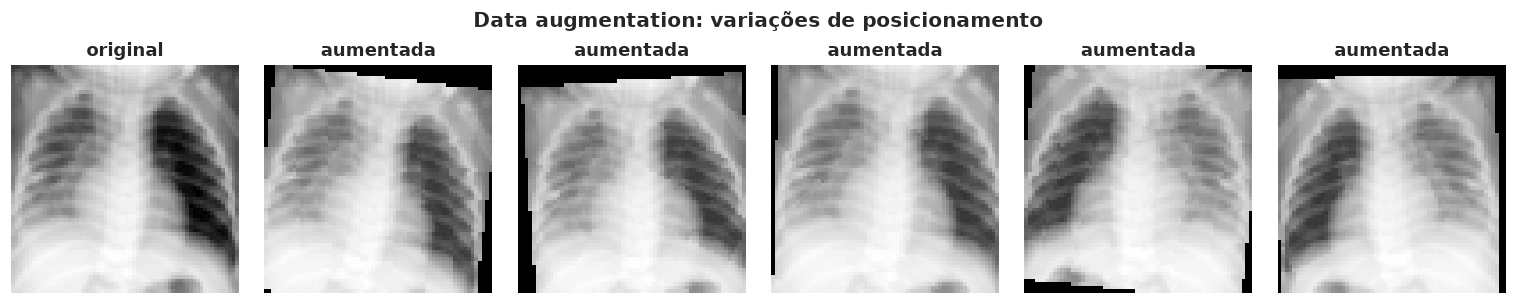

In [ ]:
# a mesma radiografia passando 5 vezes pelo augmentation
exemplo = Image.fromarray(imgs['train'][escolhidos[6]])

fig, axes = plt.subplots(1, 6, figsize=(14, 2.8))
axes[0].imshow(exemplo, cmap='gray')
axes[0].set_title('original', fontweight='bold')
for ax in axes[1:]:
    ax.imshow(augment(exemplo), cmap='gray')
    ax.set_title('aumentada')
for ax in axes:
    ax.axis('off')
fig.suptitle('Data augmentation: variações de posicionamento', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Criamos os datasets com as transformações e os `DataLoader`s, que entregam as imagens em lotes
(*batches*) de 128 para a rede. Só o treino é embaralhado.

In [14]:
datasets = {
    'train': DataClass(split='train', transform=train_tf, **kwargs),
    'val': DataClass(split='val', transform=eval_tf, **kwargs),
    'test': DataClass(split='test', transform=eval_tf, **kwargs),
}

generator = torch.Generator().manual_seed(SEED)
loaders = {
    split: DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == 'train'),
                      generator=generator if split == 'train' else None)
    for split, ds in datasets.items()
}

x_batch, y_batch = next(iter(loaders['train']))
print(f"lote de imagens: {tuple(x_batch.shape)}  (batch, canais, altura, largura)")
print(f"lote de rotulos: {tuple(y_batch.shape)} | faixa de valores: [{x_batch.min():.2f}, {x_batch.max():.2f}]")

lote de imagens: (128, 1, 64, 64)  (batch, canais, altura, largura)
lote de rotulos: (128, 1) | faixa de valores: [-1.00, 0.99]


### 5. Arquitetura da CNN

Treinamos uma **CNN compacta do zero**, pensada para convergir em CPU em poucos minutos.
Ela é formada por **3 blocos convolucionais** seguidos de uma **cabeça densa**:

| Componente | Função |
|---|---|
| `Conv2d 3×3` (×2 por bloco) | detecta padrões locais: bordas no 1º bloco, texturas no 2º, estruturas (opacidades) no 3º |
| `BatchNorm2d` | normaliza as ativações; acelera e estabiliza o treino |
| `ReLU` | não linearidade |
| `MaxPool2d(2)` | reduz a resolução pela metade, aumentando o campo de visão das camadas seguintes |
| `AdaptiveAvgPool2d(1)` | resume cada mapa de características em um número; torna a rede independente da resolução de entrada (28, 64, ...) |
| `Dropout` | desliga neurônios aleatoriamente no treino, reduzindo sobreajuste |
| `Linear(64, 1)` | saída única (*logit*); a sigmoide transforma em probabilidade de pneumonia |

O número de filtros dobra a cada bloco (32 → 64 → 128): a resolução cai e a rede compensa com
mais canais para representar padrões mais abstratos.

In [ ]:
def build_cnn(in_channels=1, dropout=0.35):
    # bloco: Conv -> BN -> ReLU -> Conv -> BN -> ReLU -> MaxPool
    def block(cin, cout):
        return nn.Sequential(
            nn.Conv2d(cin, cout, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(cout),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

    return nn.Sequential(
        block(in_channels, 32),
        block(32, 64),
        block(64, 128),
        nn.AdaptiveAvgPool2d(1),
        nn.Flatten(),
        nn.Dropout(dropout),
        nn.Linear(128, 64),
        nn.ReLU(inplace=True),
        nn.Dropout(dropout / 2),
        nn.Linear(64, 1),  # logit unico -> BCEWithLogitsLoss
    )


model = build_cnn()
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(model)
print(f"\nParametros treinaveis: {n_params:,}".replace(',', '.'))

Sequential(
  (0): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (1): Sequential(
    (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
   

São cerca de 300 mil parâmetros — pequena para os padrões de visão computacional (uma ResNet-18
tem 11 milhões), o que é adequado para ~4.700 imagens de treino e reduz o risco de sobreajuste.

### 6. Treinamento

Decisões de treino:

- **Função de perda:** `BCEWithLogitsLoss` (entropia cruzada binária) com
  **`pos_weight = n_normais / n_pneumonias`**. Como há ~3× mais pneumonias, cada erro em uma
  radiografia normal passa a pesar mais, e a rede não aprende simplesmente a dizer "pneumonia"
  sempre.
- **Otimizador:** `AdamW` (Adam com *weight decay*, outra forma de regularização).
- **Taxa de aprendizado:** decai em cosseno ao longo das épocas (`CosineAnnealingLR`), com
  passos grandes no início e ajuste fino no final.
- **Seleção de época pela ROC AUC de validação**, e não pela acurácia. Ao final, a rede volta
  aos pesos da melhor época (equivalente a um *early stopping*). A AUC mede a capacidade de
  **ordenar** pacientes doentes acima de saudáveis, independente de limiar e do desbalanceamento.

Separação dos conjuntos: o **treino** ajusta os pesos; a **validação** escolhe a época e o
limiar de decisão; o **teste** é usado uma única vez, no final, para a avaliação.

In [ ]:
@dataclass
class CNNHistory:
    # historico de treino, epoca a epoca
    train_loss: list = field(default_factory=list)
    val_loss: list = field(default_factory=list)
    train_auc: list = field(default_factory=list)
    val_auc: list = field(default_factory=list)
    best_epoch: int = 0
    best_val_auc: float = 0.0


def predict_scores(model, loader, device=DEVICE):
    # roda o modelo em modo avaliacao e devolve (y_true, prob_pneumonia, perda media)
    model.eval()
    criterion = nn.BCEWithLogitsLoss()
    scores, targets, losses = [], [], []
    with torch.no_grad():
        for images, batch_labels in loader:
            images = images.to(device)
            y = batch_labels.float().view(-1, 1).to(device)
            logits = model(images)
            losses.append(criterion(logits, y).item() * len(y))
            scores.append(torch.sigmoid(logits).cpu().numpy().ravel())
            targets.append(batch_labels.numpy().ravel())
    y_true = np.concatenate(targets).astype(int)
    return y_true, np.concatenate(scores), float(np.sum(losses) / len(y_true))


def train_cnn(model, loaders, epochs=EPOCHS, lr=LR, weight_decay=WEIGHT_DECAY, device=DEVICE):
    model = model.to(device)

    # peso da classe positiva = n_negativos / n_positivos no treino
    y_train = labels['train']
    pos_weight = torch.tensor([(y_train == 0).sum() / (y_train == 1).sum()], dtype=torch.float32).to(device)
    print(f"pos_weight aplicado a perda = {pos_weight.item():.3f}")

    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    history = CNNHistory()
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(1, epochs + 1):
        model.train()
        running, seen = 0.0, 0
        for images, batch_labels in loaders['train']:
            images = images.to(device)
            y = batch_labels.float().view(-1, 1).to(device)

            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(images), y)
            loss.backward()
            optimizer.step()

            running += loss.item() * len(y)
            seen += len(y)
        scheduler.step()

        y_tr, s_tr, _ = predict_scores(model, loaders['train'], device)
        y_va, s_va, val_loss = predict_scores(model, loaders['val'], device)
        train_auc, val_auc = roc_auc_score(y_tr, s_tr), roc_auc_score(y_va, s_va)

        history.train_loss.append(running / seen)
        history.val_loss.append(val_loss)
        history.train_auc.append(float(train_auc))
        history.val_auc.append(float(val_auc))

        marker = ''
        if val_auc > history.best_val_auc:
            history.best_val_auc = float(val_auc)
            history.best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            marker = '  <- melhor'

        print(f"epoca {epoch:2d}/{epochs} | perda treino {history.train_loss[-1]:.4f} | "
              f"perda val {val_loss:.4f} | AUC treino {train_auc:.4f} | AUC val {val_auc:.4f}{marker}")

    #volta para os pesos da melhor epoca
    model.load_state_dict(best_state)
    print(f"\nMelhor epoca: {history.best_epoch} (AUC de validacao = {history.best_val_auc:.4f})")
    return model, history

In [17]:
%%time
set_seed()
model = build_cnn()
model, history = train_cnn(model, loaders)

pos_weight aplicado a perda = 0.347
epoca  1/15 | perda treino 0.1637 | perda val 1.5532 | AUC treino 0.9351 | AUC val 0.9277  <- melhor
epoca  2/15 | perda treino 0.0996 | perda val 0.1595 | AUC treino 0.9858 | AUC val 0.9808  <- melhor
epoca  3/15 | perda treino 0.0893 | perda val 0.1812 | AUC treino 0.9841 | AUC val 0.9763
epoca  4/15 | perda treino 0.0806 | perda val 0.1337 | AUC treino 0.9904 | AUC val 0.9853  <- melhor
epoca  5/15 | perda treino 0.0728 | perda val 0.1563 | AUC treino 0.9916 | AUC val 0.9832
epoca  6/15 | perda treino 0.0688 | perda val 0.3489 | AUC treino 0.9935 | AUC val 0.9897  <- melhor
epoca  7/15 | perda treino 0.0597 | perda val 0.1455 | AUC treino 0.9933 | AUC val 0.9908  <- melhor
epoca  8/15 | perda treino 0.0583 | perda val 0.2079 | AUC treino 0.9930 | AUC val 0.9916  <- melhor
epoca  9/15 | perda treino 0.0505 | perda val 0.1153 | AUC treino 0.9950 | AUC val 0.9941  <- melhor
epoca 10/15 | perda treino 0.0552 | perda val 0.1233 | AUC treino 0.9945 | AU

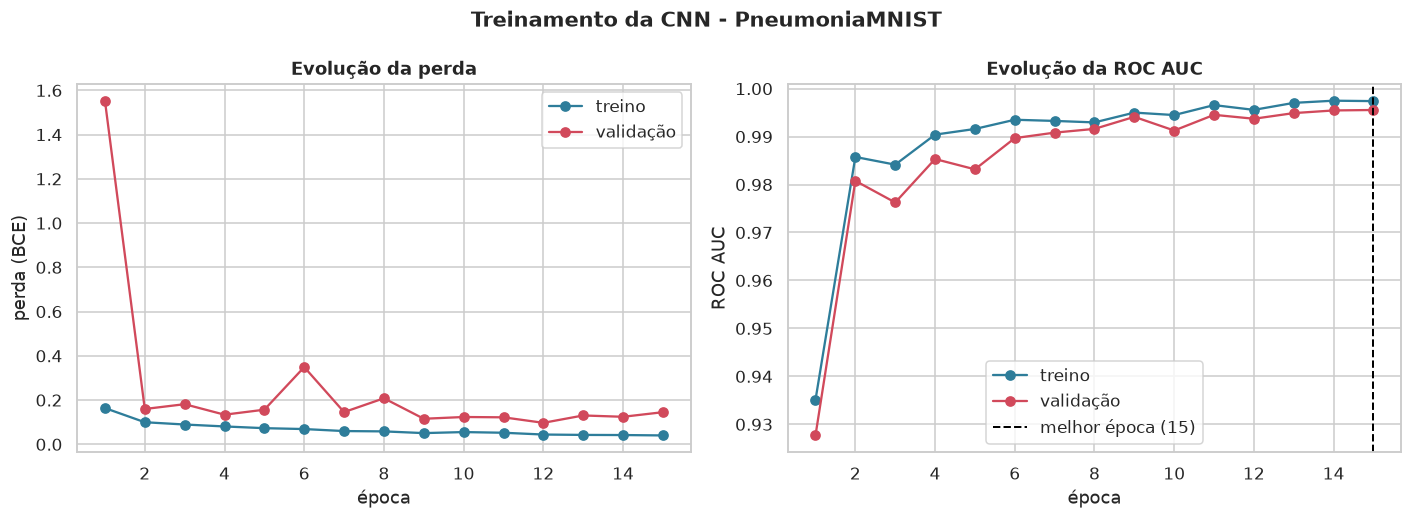

In [18]:
epocas = range(1, len(history.train_loss) + 1)
fig, (ax_loss, ax_auc) = plt.subplots(1, 2, figsize=(13, 4.8))

ax_loss.plot(epocas, history.train_loss, 'o-', label='treino', color=COR_NORMAL)
ax_loss.plot(epocas, history.val_loss, 'o-', label='validação', color=COR_PNEUMONIA)
ax_loss.set(xlabel='época', ylabel='perda (BCE)', title='Evolução da perda')
ax_loss.legend()

ax_auc.plot(epocas, history.train_auc, 'o-', label='treino', color=COR_NORMAL)
ax_auc.plot(epocas, history.val_auc, 'o-', label='validação', color=COR_PNEUMONIA)
ax_auc.axvline(history.best_epoch, ls='--', color='black', lw=1.3, label=f'melhor época ({history.best_epoch})')
ax_auc.set(xlabel='época', ylabel='ROC AUC', title='Evolução da ROC AUC')
ax_auc.legend()

fig.suptitle('Treinamento da CNN - PneumoniaMNIST', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

**Como ler as curvas.** A perda de treino deve cair de forma contínua. Se a perda de validação
passasse a **subir** enquanto a de treino cai, seria sinal de **sobreajuste** (a rede decorando o
treino). A perda de treino inclui o `pos_weight` e é medida em imagens aumentadas, então não é
diretamente comparável à de validação; o mais informativo é a **tendência**.

Curvas de AUC de treino e validação próximas e altas indicam que a rede generaliza bem para
radiografias que não viu. A combinação de augmentation, dropout, weight decay e seleção pela
melhor época mantém o sobreajuste sob controle.

### 7. Escolha da métrica e calibração do limiar de decisão

Em triagem de pneumonia, os dois erros possíveis têm custos muito diferentes:

- **Falso negativo** (pneumonia classificada como normal): a criança é liberada sem
  tratamento, e a infecção pode evoluir para quadros graves. **É o erro mais caro.**
- **Falso positivo** (normal classificada como pneumonia): gera uma revisão adicional pelo
  radiologista. Consome tempo, mas é reversível.

Por isso a métrica principal é o **recall (sensibilidade) da classe pneumonia**, com o
**F1-score** e a **precisão** como contrapeso, para que o modelo não vire um alarme permanente.
Também acompanhamos a **especificidade** (acerto entre os normais) e a **ROC AUC**.

**Limiar clínico.** Por padrão, um classificador diz "pneumonia" quando a probabilidade é
≥ 0,50 — um valor arbitrário. Aqui fixamos primeiro a sensibilidade mínima aceitável
(`TARGET_RECALL = 0.98`) e escolhemos, **no conjunto de validação**, o **maior** limiar que ainda a
atinge: entre todos os limiares seguros, é o que gera menos falsos positivos. O limiar vira um
parâmetro clínico, que pode ser renegociado com a equipe médica.

In [ ]:
def compute_metrics(y_true, y_scores, threshold=0.5):
    # conjunto completo de metricas para um limiar
    y_true = np.asarray(y_true).astype(int)
    y_pred = (y_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        'threshold': float(threshold),
        'recall': recall_score(y_true, y_pred, zero_division=0),
        'f1': f1_score(y_true, y_pred, zero_division=0),
        'precision': precision_score(y_true, y_pred, zero_division=0),
        'specificity': tn / (tn + fp) if (tn + fp) else 0.0,
        'accuracy': accuracy_score(y_true, y_pred),
        'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
        'roc_auc': roc_auc_score(y_true, y_scores),
        'pr_auc': average_precision_score(y_true, y_scores),
        'mcc': matthews_corrcoef(y_true, y_pred),
        'brier': brier_score_loss(y_true, y_scores),
        'tp': int(tp), 'fn': int(fn), 'fp': int(fp), 'tn': int(tn),
    }


def tune_threshold(y_true, y_scores, target_recall=TARGET_RECALL):
    # varre todos os limiares possiveis e escolhe o MAIOR que garante target_recall
    grid = np.unique(np.round(np.concatenate([y_scores, [0.0, 1.0]]), 6))
    curve = pd.DataFrame([compute_metrics(y_true, y_scores, thr) for thr in grid])

    elegiveis = curve[curve['recall'] >= target_recall]
    if elegiveis.empty:  # nenhum limiar atinge a meta -> usamos o mais sensivel
        best = curve.loc[curve['recall'].idxmax()]
    else:
        best = elegiveis.loc[elegiveis['threshold'].idxmax()]
    return float(best['threshold']), curve

In [20]:
y_val, s_val, _ = predict_scores(model, loaders['val'])
threshold, curva_limiar = tune_threshold(y_val, s_val)

linha = curva_limiar.loc[curva_limiar['threshold'] == threshold].iloc[0]
print(f"Limiar clinico escolhido na validacao: {threshold:.4f}")
print(f"  recall = {linha['recall']:.4f} | precisao = {linha['precision']:.4f} | "
      f"especificidade = {linha['specificity']:.4f}")

Limiar clinico escolhido na validacao: 0.0665
  recall = 0.9820 | precisao = 0.9795 | especificidade = 0.9407


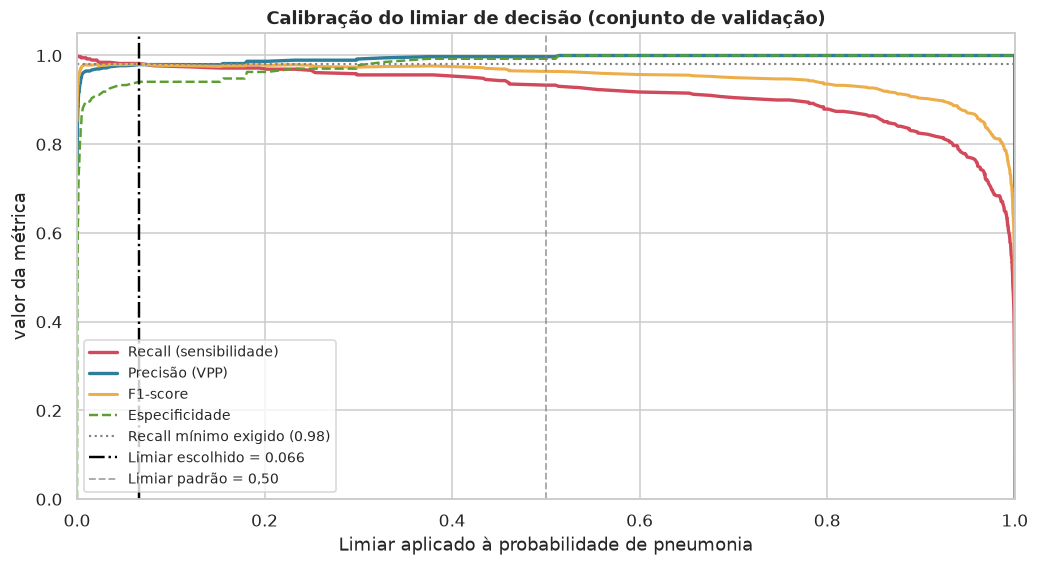

In [21]:
curva = curva_limiar.sort_values('threshold')

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.plot(curva['threshold'], curva['recall'], label='Recall (sensibilidade)', color=COR_PNEUMONIA, lw=2.2)
ax.plot(curva['threshold'], curva['precision'], label='Precisão (VPP)', color=COR_NORMAL, lw=2.2)
ax.plot(curva['threshold'], curva['f1'], label='F1-score', color='#EDAE49', lw=2)
ax.plot(curva['threshold'], curva['specificity'], label='Especificidade', color='#5C9E31', lw=1.6, ls='--')
ax.axhline(TARGET_RECALL, color='grey', ls=':', lw=1.4, label=f'Recall mínimo exigido ({TARGET_RECALL:.2f})')
ax.axvline(threshold, color='black', ls='-.', lw=1.6, label=f'Limiar escolhido = {threshold:.3f}')
ax.axvline(0.5, color='grey', ls='--', lw=1.2, alpha=0.7, label='Limiar padrão = 0,50')
ax.set(xlabel='Limiar aplicado à probabilidade de pneumonia', ylabel='valor da métrica',
       title='Calibração do limiar de decisão (conjunto de validação)', xlim=(0, 1), ylim=(0, 1.05))
ax.legend(loc='lower left', fontsize=9)
plt.show()

O gráfico mostra o **trade-off**: ao baixar o limiar, o recall sobe (menos pneumonias perdidas)
e a especificidade cai (mais radiografias normais sinalizadas). O limiar escolhido é o ponto mais
à direita em que o recall ainda está acima da linha pontilhada.

### 8. Avaliação no conjunto de teste

O conjunto de teste (624 radiografias) é usado **uma única vez**, com o modelo e o limiar já
fixados. Comparamos o limiar padrão (0,50) com o limiar clínico calibrado na validação.

In [22]:
y_test, s_test, _ = predict_scores(model, loaders['test'])

resultados = pd.DataFrame({
    'CNN @ limiar padrão 0.50': compute_metrics(y_test, s_test, 0.5),
    f'CNN @ limiar clínico {threshold:.3f}': compute_metrics(y_test, s_test, threshold),
}).T
resultados[['tp', 'fn', 'fp', 'tn']] = resultados[['tp', 'fn', 'fp', 'tn']].astype(int)
resultados.round(4)

,threshold,recall,f1,precision,specificity,accuracy,balanced_accuracy,roc_auc,pr_auc,mcc,brier,tp,fn,fp,tn
CNN @ limiar padrão 0.50,0.5000,0.9615,0.9446,0.9282,0.8761,0.9295,0.9188,0.9695,0.9795,0.8487,0.0601,375,15,29,205
CNN @ limiar clínico 0.066,0.0665,0.9897,0.9093,0.8410,0.6880,0.8766,0.8389,0.9695,0.9795,0.7440,0.0601,386,4,73,161


In [23]:
y_pred_test = (s_test >= threshold).astype(int)
print(f"Limiar clinico = {threshold:.3f}\n")
print(classification_report(y_test, y_pred_test, target_names=list(CLASS_LABELS), digits=4))

Limiar clinico = 0.066

              precision    recall  f1-score   support

      Normal     0.9758    0.6880    0.8070       234
   Pneumonia     0.8410    0.9897    0.9093       390

    accuracy                         0.8766       624
   macro avg     0.9084    0.8389    0.8582       624
weighted avg     0.8915    0.8766    0.8709       624



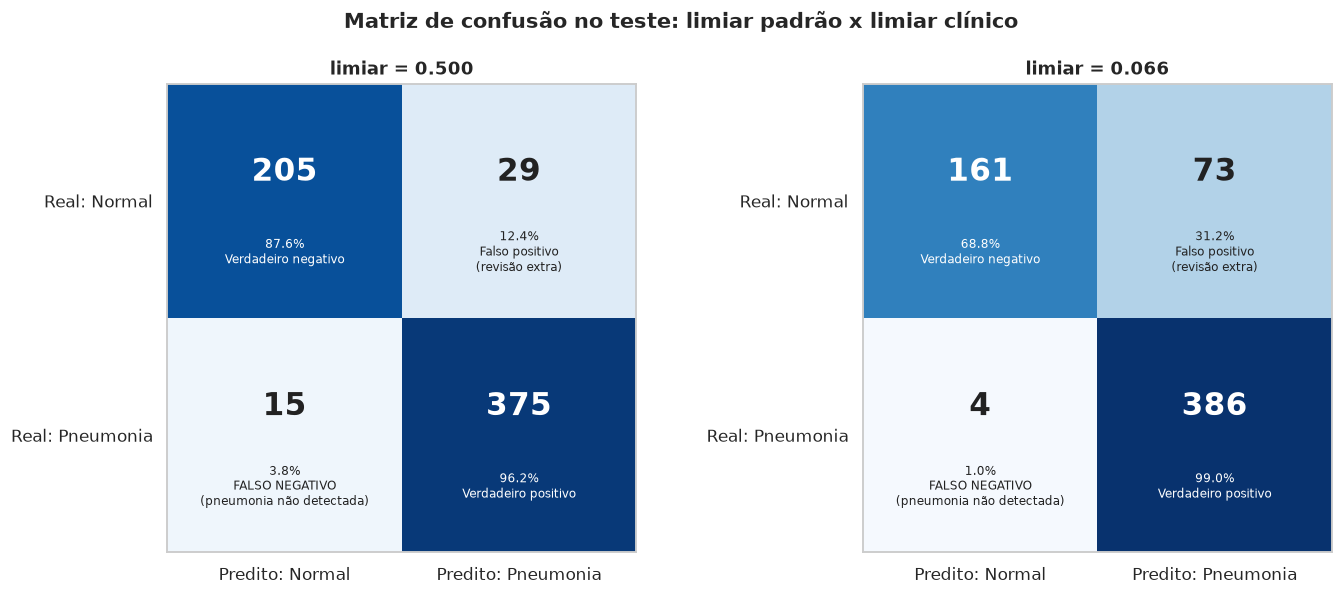

In [ ]:
def plot_confusion(y_true, y_scores, thr, ax):
    # matriz de confusao com contagem absoluta e % por classe real
    y_pred = (y_scores >= thr).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    nomes = [['Verdadeiro negativo', 'Falso positivo\n(revisão extra)'],
             ['FALSO NEGATIVO\n(pneumonia não detectada)', 'Verdadeiro positivo']]

    ax.imshow(pct, cmap='Blues', vmin=0, vmax=100)
    for i in range(2):
        for j in range(2):
            cor = 'white' if pct[i, j] > 55 else '#222222'
            ax.text(j, i - 0.12, f"{cm[i, j]}", ha='center', va='center', fontsize=20, fontweight='bold', color=cor)
            ax.text(j, i + 0.22, f"{pct[i, j]:.1f}%\n{nomes[i][j]}", ha='center', va='center', fontsize=8, color=cor)
    ax.set_xticks([0, 1], [f'Predito: {c}' for c in CLASS_LABELS])
    ax.set_yticks([0, 1], [f'Real: {c}' for c in CLASS_LABELS])
    ax.set_title(f'limiar = {thr:.3f}')
    ax.grid(False)


fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_confusion(y_test, s_test, 0.5, axes[0])
plot_confusion(y_test, s_test, threshold, axes[1])
fig.suptitle('Matriz de confusão no teste: limiar padrão x limiar clínico', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

A matriz de confusão deixa explícito o custo de cada limiar: o limiar clínico **troca falsos
negativos por falsos positivos**. Cada pneumonia a menos perdida custa algumas radiografias
normais a mais enviadas para revisão — uma troca aceitável em triagem, porque o falso positivo
ainda passa pelo radiologista.

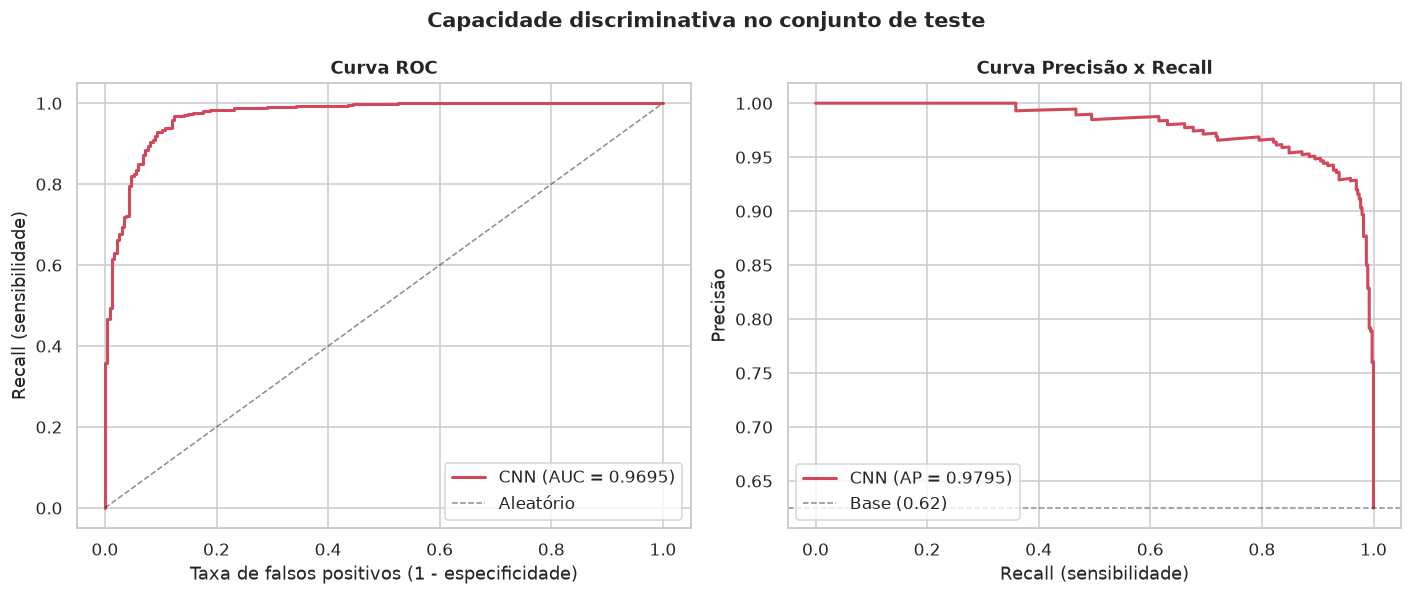

In [25]:
fig, (ax_roc, ax_pr) = plt.subplots(1, 2, figsize=(13, 5.5))

fpr, tpr, _ = roc_curve(y_test, s_test)
ax_roc.plot(fpr, tpr, color=COR_PNEUMONIA, lw=2, label=f'CNN (AUC = {roc_auc_score(y_test, s_test):.4f})')
ax_roc.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Aleatório')
ax_roc.set(xlabel='Taxa de falsos positivos (1 - especificidade)', ylabel='Recall (sensibilidade)', title='Curva ROC')
ax_roc.legend(loc='lower right')

prec, rec, _ = precision_recall_curve(y_test, s_test)
ax_pr.plot(rec, prec, color=COR_PNEUMONIA, lw=2, label=f'CNN (AP = {average_precision_score(y_test, s_test):.4f})')
ax_pr.axhline(y_test.mean(), ls='--', c='k', lw=1, alpha=0.5, label=f'Base ({y_test.mean():.2f})')
ax_pr.set(xlabel='Recall (sensibilidade)', ylabel='Precisão', title='Curva Precisão x Recall')
ax_pr.legend(loc='lower left')

fig.suptitle('Capacidade discriminativa no conjunto de teste', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

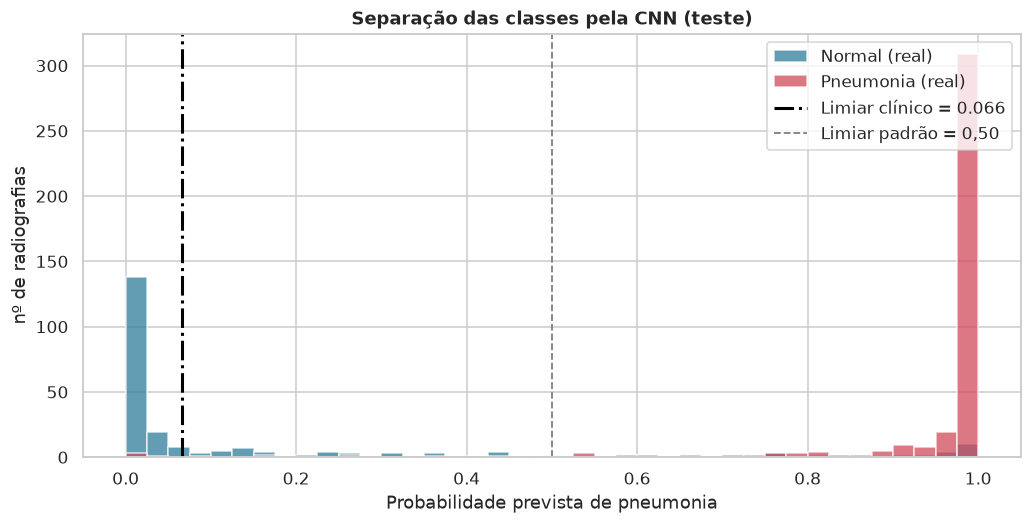

In [26]:
fig, ax = plt.subplots(figsize=(11, 5))
bins = np.linspace(0, 1, 41)
ax.hist(s_test[y_test == 0], bins=bins, alpha=0.75, label='Normal (real)', color=COR_NORMAL)
ax.hist(s_test[y_test == 1], bins=bins, alpha=0.75, label='Pneumonia (real)', color=COR_PNEUMONIA)
ax.axvline(threshold, color='black', ls='-.', lw=2, label=f'Limiar clínico = {threshold:.3f}')
ax.axvline(0.5, color='grey', ls='--', lw=1.2, label='Limiar padrão = 0,50')
ax.set(xlabel='Probabilidade prevista de pneumonia', ylabel='nº de radiografias',
       title='Separação das classes pela CNN (teste)')
ax.legend()
plt.show()

**Leitura dos resultados.** A ROC AUC mede o quanto a rede ordena bem os pacientes (1,0 =
perfeito; 0,5 = aleatório). No histograma, as pneumonias se concentram perto de 1 e a maior parte
das normais perto de 0. A cauda de radiografias **normais com probabilidade alta** é a origem dos
falsos positivos — e por isso a especificidade é a métrica mais fraca do modelo.

Também é esperado que o desempenho no teste seja **um pouco inferior** ao da validação: como
vimos na exploração, o teste tem proporção de classes diferente, e foi montado separadamente
pelos autores da base.

### 9. Análise de erros

Mostramos os **erros mais confiantes** do modelo (os que estão mais longe do limiar) junto com
alguns acertos. São esses casos que a equipe clínica precisaria inspecionar para entender as
limitações do modelo.

Erros no teste: 77 de 624 (4 falsos negativos, 73 falsos positivos)


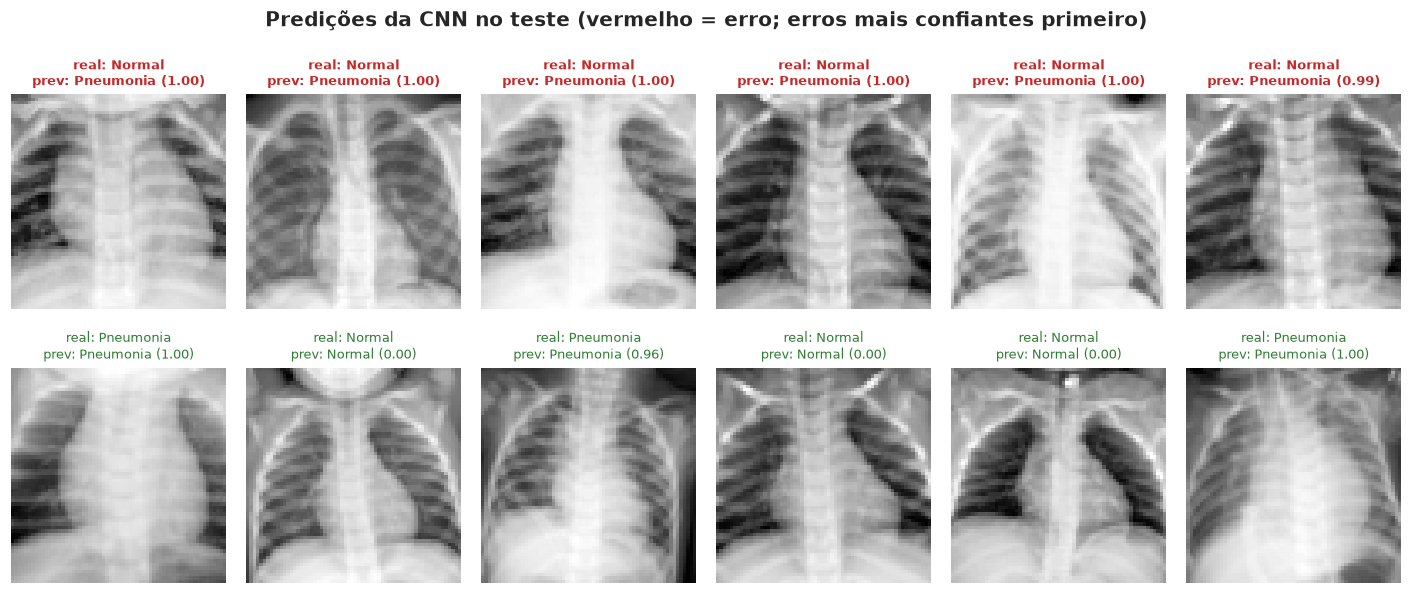

In [ ]:
X_test_img, y_true_test = imgs['test'], labels['test']
errados = np.where(y_pred_test != y_true_test)[0]
certos = np.where(y_pred_test == y_true_test)[0]
print(f"Erros no teste: {len(errados)} de {len(y_true_test)} "
      f"({(y_true_test[errados] == 1).sum()} falsos negativos, {(y_true_test[errados] == 0).sum()} falsos positivos)")

# ate 6 erros mais confiantes + acertos aleatorios
n_err = min(len(errados), 6)
mostrar = np.concatenate([
    errados[np.argsort(-np.abs(s_test[errados] - threshold))][:n_err],
    rng.choice(certos, 12 - n_err, replace=False),
])

fig, axes = plt.subplots(2, 6, figsize=(13, 5.8))
for ax, idx in zip(axes.ravel(), mostrar):
    ok = y_pred_test[idx] == y_true_test[idx]
    ax.imshow(X_test_img[idx], cmap='gray')
    ax.set_title(f"real: {CLASS_LABELS[y_true_test[idx]]}\nprev: {CLASS_LABELS[y_pred_test[idx]]} ({s_test[idx]:.2f})",
                 fontsize=8.5, color='#2E7D32' if ok else '#C62828', fontweight='normal' if ok else 'bold')
    ax.axis('off')
fig.suptitle('Predições da CNN no teste (vermelho = erro; erros mais confiantes primeiro)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

Os falsos positivos costumam ser radiografias normais com **baixo contraste**, má inspiração ou
estruturas sobrepostas (coração, clavículas) que imitam opacidades na baixa resolução de 64×64.
Os falsos negativos tendem a ser pneumonias **discretas**, com pouca opacidade visível. Ambos
são casos em que a revisão humana é indispensável.

### 10. Interpretabilidade com Grad-CAM

Para os dados tabulares usamos *feature importance* e SHAP. Para imagens, o equivalente é o
**Grad-CAM** (*Gradient-weighted Class Activation Mapping*, Selvaraju et al., 2017): ele usa os
gradientes da saída em relação à **última camada convolucional** para gerar um mapa de calor com
as regiões da imagem que mais pesaram na decisão.

Funcionamento:

1. guardamos as ativações da última convolução (*forward hook*) e seus gradientes (*backward hook*);
2. a média dos gradientes de cada canal vira o **peso** desse canal;
3. somamos os canais ponderados, aplicamos ReLU (só o que aumenta a probabilidade de pneumonia)
   e redimensionamos o mapa para o tamanho da imagem.

Isso permite ao radiologista **auditar** o modelo: a rede olhou para o campo pulmonar ou para um
artefato irrelevante (borda, texto, marcador metálico)?

In [ ]:
def grad_cam(model, image_tensor, device=DEVICE):
    # devolve (mapa de calor normalizado 0-1, probabilidade de pneumonia)
    model = model.to(device).eval()
    target_layer = [m for m in model.modules() if isinstance(m, nn.Conv2d)][-1]

    store = {}
    h1 = target_layer.register_forward_hook(lambda m, i, o: store.__setitem__('act', o.detach()))
    h2 = target_layer.register_full_backward_hook(lambda m, gi, go: store.__setitem__('grad', go[0].detach()))
    try:
        x = image_tensor.unsqueeze(0).to(device).requires_grad_(True)
        logit = model(x)
        model.zero_grad(set_to_none=True)
        logit.backward()
    finally:
        h1.remove()
        h2.remove()

    weights = store['grad'].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * store['act']).sum(dim=1, keepdim=True))
    cam = F.interpolate(cam, size=image_tensor.shape[-2:], mode='bilinear', align_corners=False)
    cam = cam.squeeze().cpu().numpy()
    if cam.max() > cam.min():
        cam = (cam - cam.min()) / (cam.max() - cam.min())
    return cam, float(torch.sigmoid(logit).item())

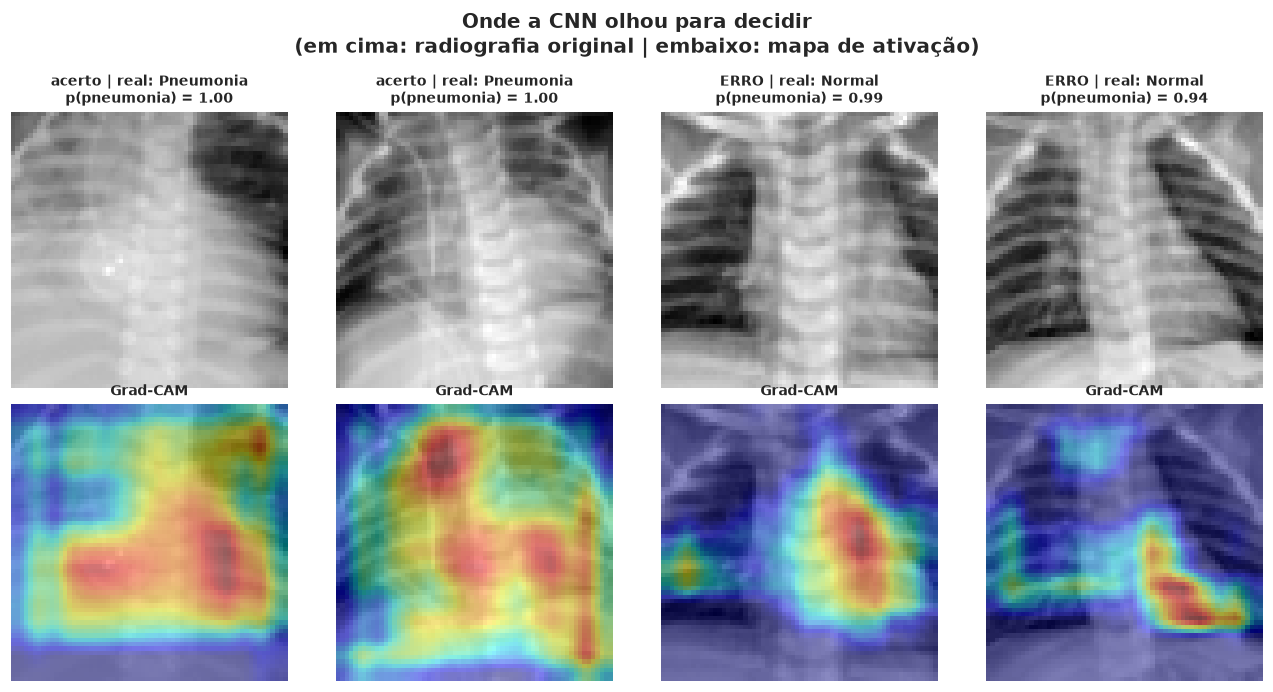

In [ ]:
# 2 acertos mais confiantes + 2 erros
confiantes = [i for i in np.argsort(-np.abs(s_test - 0.5)) if y_pred_test[i] == y_true_test[i]][:2]
casos = [int(i) for i in list(confiantes) + list(errados[:2])]

fig, axes = plt.subplots(2, len(casos), figsize=(3 * len(casos), 6.4))
for col, idx in enumerate(casos):
    image_tensor, _ = datasets['test'][idx]
    cam, prob = grad_cam(model, image_tensor)
    tipo = 'acerto' if y_pred_test[idx] == y_true_test[idx] else 'ERRO'

    axes[0, col].imshow(X_test_img[idx], cmap='gray')
    axes[0, col].set_title(f"{tipo} | real: {CLASS_LABELS[y_true_test[idx]]}\np(pneumonia) = {prob:.2f}", fontsize=9)
    axes[1, col].imshow(X_test_img[idx], cmap='gray')
    axes[1, col].imshow(cam, cmap='jet', alpha=0.45)
    axes[1, col].set_title('Grad-CAM', fontsize=9)
    for row in (0, 1):
        axes[row, col].axis('off')

fig.suptitle('Onde a CNN olhou para decidir\n(em cima: radiografia original | embaixo: mapa de ativação)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Interpretação.** Um modelo confiável deve concentrar a ativação (regiões quentes, em vermelho)
**dentro dos campos pulmonares**, onde estão as opacidades. Se o mapa destacasse bordas, textos
ou a região fora do tórax, seria sinal de que a rede aprendeu um **atalho** (por exemplo, uma
marca do aparelho associada a um dos hospitais) — um risco conhecido em modelos de radiografia.

Nos erros, o Grad-CAM ajuda a entender a confusão: um falso positivo que ativa sobre a silhueta
do coração ou sobre uma clavícula indica que a rede confundiu estruturas normais com opacidade.
Na resolução de 64×64 o mapa é grosseiro (a última convolução tem 16×16 posições), então ele
indica **regiões**, não lesões precisas.

### 11. Salvando o modelo

Salvamos os pesos da CNN junto com o limiar clínico e as métricas de teste, para que o modelo
possa ser reutilizado sem novo treino. O checkpoint `.pt` fica em `models/` (ignorado pelo Git)
e as métricas em `models/metrics/`.

In [30]:
metricas_clinico = {k: round(float(v), 4) for k, v in compute_metrics(y_test, s_test, threshold).items()}
metricas_padrao = {k: round(float(v), 4) for k, v in compute_metrics(y_test, s_test, 0.5).items()}

ckpt_path = MODELS_DIR / 'cnn_pneumonia.pt'
torch.save({
    'state_dict': model.state_dict(),
    'image_size': IMAGE_SIZE,
    'threshold': threshold,
    'class_labels': list(CLASS_LABELS),
    'n_params': n_params,
    'test_metrics': metricas_clinico,
    'trained_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}, ckpt_path)

manifesto = {
    'dataset': 'PneumoniaMNIST (MedMNIST v2 / Chest X-Ray - Kermany et al.)',
    'resolucao': f'{IMAGE_SIZE}x{IMAGE_SIZE}',
    'n_treino': len(datasets['train']), 'n_validacao': len(datasets['val']), 'n_teste': len(datasets['test']),
    'epocas': EPOCHS, 'melhor_epoca': history.best_epoch,
    'auc_validacao': round(history.best_val_auc, 4),
    'parametros_treinaveis': n_params,
    'limiar_clinico': round(threshold, 4),
    'teste_limiar_padrao': metricas_padrao,
    'teste_limiar_clinico': metricas_clinico,
}
metrics_path = MODELS_DIR / 'metrics' / 'cnn_pneumonia_teste.json'
metrics_path.write_text(json.dumps(manifesto, indent=2, ensure_ascii=False), encoding='utf-8')

print(f"Checkpoint salvo em {ckpt_path} ({ckpt_path.stat().st_size / 1024**2:.1f} MB)")
print(f"Metricas salvas em {metrics_path}")

Checkpoint salvo em /home/vinic/fiap/fase_1/tech_challenge_worktress/cnn_task/models/cnn_pneumonia.pt (1.1 MB)
Metricas salvas em /home/vinic/fiap/fase_1/tech_challenge_worktress/cnn_task/models/metrics/cnn_pneumonia_teste.json


Para reutilizar o modelo depois:

```python
ckpt = torch.load(MODELS_DIR / 'cnn_pneumonia.pt')
model = build_cnn()
model.load_state_dict(ckpt['state_dict'])
threshold = ckpt['threshold']
```

### 12. Discussão crítica e conclusão

#### Resumo do que foi feito

- **Dados:** PneumoniaMNIST (5.856 radiografias pediátricas, versão curada da base de Kermany et
  al. sugerida no enunciado), com divisão oficial em treino / validação / teste.
- **Pré-processamento:** normalização dos pixels e *data augmentation* geométrico leve no treino.
- **Modelo:** CNN compacta treinada do zero (~300 mil parâmetros), com perda ponderada para o
  desbalanceamento e seleção de época pela ROC AUC de validação.
- **Decisão:** limiar clínico calibrado na validação para garantir recall ≥ 0,98, priorizando
  não perder pneumonias.
- **Interpretação:** Grad-CAM para verificar se a rede se baseia no campo pulmonar.

Os números exatos estão nas tabelas da seção 8. Como referência, uma execução com esta mesma
configuração obteve no teste **ROC AUC ≈ 0,97** e, no limiar clínico, **recall ≈ 0,99**
(5 pneumonias perdidas em 390) com **especificidade ≈ 0,73** — ou seja, o modelo encontra quase
todas as pneumonias ao custo de enviar cerca de 1 em cada 4 radiografias normais para revisão.

#### O modelo pode ser usado na prática? Como?

**Como ferramenta de triagem e priorização, sim; como diagnóstico autônomo, não.** Um uso
realista no hospital seria:

1. cada radiografia nova recebe uma **probabilidade de pneumonia** e o mapa Grad-CAM;
2. a fila do radiologista é **reordenada**: exames de alta suspeita são laudados primeiro;
3. exames abaixo do limiar seguem a fila normal, mas **continuam sendo laudados por um médico**;
4. o Grad-CAM é exibido como apoio visual, nunca como justificativa do laudo.

Nesse fluxo, o alto recall reduz o risco de um caso grave esperar na fila, e os falsos positivos
apenas antecipam exames que seriam vistos de qualquer forma. **O médico sempre tem a palavra
final no diagnóstico.**

#### Limitações

- **População restrita:** apenas crianças de 1 a 5 anos de um único centro na China. O modelo
  **não deve** ser aplicado a adultos ou a outros equipamentos sem nova validação.
- **Baixa resolução:** 64×64 pixels descartam detalhes finos que o radiologista usa; pneumonias
  discretas podem passar despercebidas.
- **Especificidade moderada:** o limiar clínico gera um volume relevante de falsos positivos,
  que precisa caber na capacidade da equipe.
- **Tarefa simplificada:** a base não distingue pneumonia **bacteriana** de **viral**, que têm
  condutas diferentes, nem outras doenças pulmonares.
- **Rótulos:** feitos por especialistas, mas sem confirmação laboratorial — há ruído de rótulo.
- **Calibração e deriva:** as probabilidades devem ser recalibradas e monitoradas ao longo do
  tempo, já que a prevalência e os equipamentos mudam.

#### Próximos passos

- **Transfer learning** com redes pré-treinadas (ResNet, DenseNet) em resolução maior (224×224);
- **validação externa** em radiografias de outros hospitais e de adultos;
- **calibração das probabilidades** (Platt / isotônica) e estudo prospectivo com radiologistas;
- extensão para classificação multiclasse (normal / bacteriana / viral).

#### Referências

- Kermany, D. S. et al. (2018). *Identifying Medical Diagnoses and Treatable Diseases by
  Image-Based Deep Learning*. Cell, 172(5), 1122–1131.
- Yang, J. et al. (2023). *MedMNIST v2 — A large-scale lightweight benchmark for 2D and 3D
  biomedical image classification*. Scientific Data, 10, 41.
- Selvaraju, R. R. et al. (2017). *Grad-CAM: Visual Explanations from Deep Networks via
  Gradient-based Localization*. ICCV.
- Base no Kaggle: https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia